In [1]:
# ============================================================
# TESTE: conectar o Python ao Ollama
# ============================================================
import ollama

# Mandar uma pergunta de teste para o modelo
resposta = ollama.chat(
    model="llama3.1:8b",
    messages=[
        {"role": "user", "content": "Responda em uma frase: o que e a Teoria Classica dos Testes?"}
    ]
)

# Mostrar a resposta
print("Resposta do agente:")
print(resposta["message"]["content"])


Resposta do agente:
A Teoria Clássica dos Testes é uma abordagem estatística que busca determinar a confiabilidade de medidas por meio de análises de consistência e reprodutibilidade.


In [9]:
from pypdf import PdfReader

caminho_prova = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\2021_PV_bacharelado_ciencia_computacao.pdf"

leitor = PdfReader(caminho_prova)
print("Numero de paginas:", len(leitor.pages))

# Juntar o texto de todas as paginas numa LISTA (sem aspas problematicas)
partes = []
for pagina in leitor.pages:
    conteudo = pagina.extract_text()
    if conteudo:
        partes.append(conteudo)

# Juntar tudo com quebra de linha
texto_completo = chr(10).join(partes)

print("Total de caracteres extraidos:", len(texto_completo))
print()

print("===== Teste: texto da pagina 14 (primeiros 800 caracteres) =====")
texto_p14 = leitor.pages[13].extract_text()
if texto_p14:
    print(texto_p14[:800])
else:
    print("Esta pagina NAO retornou texto (pode ser imagem escaneada).")


Numero de paginas: 48
Total de caracteres extraidos: 83595

===== Teste: texto da pagina 14 (primeiros 800 caracteres) =====
14 CIÊNCIA DA COMPUTAÇÃO
QuEStãO diSCuRSiVa 03 
Um corpo de conhecimento representado na lógica proposicional utiliza os conectivos lógicos de 
implicação ( ® ) que representa o condicional, conjunção ( Ù ) que representa o operador lógico AND, 
a disjunção ( Ú ) que representa o operador lógico OR e a negação ( Ø ) que representa o operador 
lógico NOT. Seja p o seguinte conjunto de fórmulas da lógica proposicional:
1.a ® Ø b
2.b Ù a
3.Ø b Ú b
seja Q o seguinte conjunto de fórmulas da lógica proposicional:
4.a Ú b
5.b ® a
e seja R a fórmula
6.Ø b ® a
Veja a tabela-verdade para estas fórmulas.
1 2 3 4 5 6
a b a ® Ø b b Ù a Ø b Ú b a Ú b b ® a Ø b ® a
F F V F V F V F
F V V F V V F V
V F V F V V V V
V V F V V V V V
Sabe-se que cada linha da tabela-verdade corresponde a uma atribuição de valo


In [10]:
import re

# ============================================================
# SEPARAR as questoes do Componente Especifico (QUESTAO 9 a 35)
# ============================================================
# Vamos usar expressao regular para achar onde cada "QUESTAO N" comeca.
# O texto tem "QUESTÃO 9", "QUESTÃO 10", etc.

# Procurar todas as ocorrencias de "QUESTAO <numero>" (ignorando acento/caixa)
# Padrao: a palavra QUESTAO seguida de um numero, mas NAO "DISCURSIVA"
padrao = re.compile(r"QUEST[ÃA]O\s+(\d{1,2})", re.IGNORECASE)

# Achar todas as posicoes
ocorrencias = [(m.group(1), m.start()) for m in padrao.finditer(texto_completo)]

print("Ocorrencias de 'QUESTAO N' encontradas:")
for numero, pos in ocorrencias:
    print(f"  Questao {numero} -> posicao {pos}")


Ocorrencias de 'QUESTAO N' encontradas:
  Questao 01 -> posicao 6653
  Questao 02 -> posicao 9165
  Questao 03 -> posicao 12255
  Questao 04 -> posicao 14228
  Questao 05 -> posicao 16818
  Questao 06 -> posicao 19090
  Questao 07 -> posicao 21203
  Questao 08 -> posicao 24552
  Questao 09 -> posicao 32193
  Questao 10 -> posicao 33508
  Questao 11 -> posicao 34748
  Questao 12 -> posicao 36727
  Questao 13 -> posicao 37909
  Questao 14 -> posicao 39451
  Questao 15 -> posicao 42388
  Questao 16 -> posicao 43768
  Questao 17 -> posicao 44785
  Questao 18 -> posicao 47531
  Questao 19 -> posicao 49044
  Questao 20 -> posicao 50515
  Questao 21 -> posicao 51655
  Questao 22 -> posicao 55173
  Questao 23 -> posicao 56887
  Questao 24 -> posicao 59706
  Questao 25 -> posicao 61508
  Questao 26 -> posicao 63541
  Questao 27 -> posicao 65280
  Questao 28 -> posicao 66379
  Questao 29 -> posicao 69447
  Questao 30 -> posicao 70810
  Questao 31 -> posicao 72486
  Questao 32 -> posicao 74244
  

In [11]:
import re

# ============================================================
# RECORTAR as questoes 9 a 35 (Componente Especifico)
# ============================================================
padrao = re.compile(r"QUEST[ÃA]O\s+(\d{1,2})", re.IGNORECASE)

# Pegar todas as ocorrencias (numero + posicao)
todas = [(int(m.group(1)), m.start()) for m in padrao.finditer(texto_completo)]

# FILTRAR: queremos so a PRIMEIRA ocorrencia de cada questao de 9 a 35,
# e so na parte da prova (posicao antes de 80000, para evitar o gabarito no fim)
questoes_posicoes = {}
for numero, pos in todas:
    if 9 <= numero <= 35 and pos < 80000:
        # Guarda so a primeira vez que a questao aparece
        if numero not in questoes_posicoes:
            questoes_posicoes[numero] = pos

# Ordenar por numero
numeros_ordenados = sorted(questoes_posicoes.keys())
print("Questoes especificas encontradas:", numeros_ordenados)
print("Total:", len(numeros_ordenados), "questoes")
print()

# Agora recortar o texto de cada questao
# (do inicio de uma ate o inicio da proxima)
questoes_texto = {}
for i, numero in enumerate(numeros_ordenados):
    inicio = questoes_posicoes[numero]
    # fim = inicio da proxima questao, ou fim do texto se for a ultima
    if i + 1 < len(numeros_ordenados):
        fim = questoes_posicoes[numeros_ordenados[i+1]]
    else:
        fim = inicio + 2500  # ultima questao: pega ~2500 caracteres
    questoes_texto[numero] = texto_completo[inicio:fim].strip()

# Mostrar um exemplo: a questao 35 (sistemas distribuidos)
print("===== Exemplo: QUESTAO 35 =====")
print(questoes_texto[35][:800])


Questoes especificas encontradas: [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35]
Total: 27 questoes

===== Exemplo: QUESTAO 35 =====
QuEStãO 35 
Um sistema distribuído é aquele no qual os componentes de hardware ou software, localizados em 
computadores interligados em rede, comunicam-se e coordenam suas ações apenas enviando mensagens 
entre si.
COULOURIS, G. et al. Sistemas distribuídos: conceitos e projeto. 5. ed., Porto Alegre: Bookman, 2013 (adaptado).
Com base na definição apresentada e nos conceitos básicos de sistemas distribuídos, assinale a opção correta.
A A existência de um relógio físico local sincronizado com um relógio global é o que permite aos usuários 
de um sistema distribuído trocarem mensagens de forma coordenada.
B A falha de um componente em um sistema distribuído peer-to-peer causa a interrupção de todos os 
demais componentes até o seu retorno.
C O compartilhamento dos recursos distribuídos entr


In [12]:
import ollama

# ============================================================
# AGENTE: classificar o TEMA de uma questao (teste com a Q35)
# ============================================================

# Lista de temas possiveis de Ciencia da Computacao (baseado no conteudo do ENADE)
# Isso ajuda o agente a escolher dentro de categorias padronizadas
temas_possiveis = [
    "Algoritmos e Estrutura de Dados",
    "Programacao",
    "Banco de Dados",
    "Redes de Computadores",
    "Sistemas Operacionais",
    "Sistemas Distribuidos",
    "Engenharia de Software",
    "Arquitetura de Computadores",
    "Teoria da Computacao",
    "Logica e Matematica",
    "Inteligencia Artificial",
    "Seguranca da Informacao",
    "Interacao Humano-Computador",
    "Computacao Grafica",
    "Compiladores"
]

# Montar o "pedido" (prompt) para o agente
def classificar_questao(texto_questao, temas):
    lista_temas = ", ".join(temas)
    prompt = f"""Voce e um especialista em Ciencia da Computacao analisando questoes de prova.

Leia a questao abaixo e identifique o TEMA principal dela.
Escolha APENAS UM tema da seguinte lista: {lista_temas}

Responda EXATAMENTE neste formato (sem explicacoes extras):
TEMA: <um tema da lista>
CONFIANCA: <alta, media ou baixa>

QUESTAO:
{texto_questao}
"""
    resposta = ollama.chat(
        model="llama3.1:8b",
        messages=[{"role": "user", "content": prompt}]
    )
    return resposta["message"]["content"]

# Testar com a Questao 35
print("Classificando a Questao 35...")
print()
resultado = classificar_questao(questoes_texto[35], temas_possiveis)
print(resultado)


Classificando a Questao 35...

TEMA: Sistemas Distribuidos
CONFIANCA: alta


In [13]:
import re
import time

# ============================================================
# AGENTE: classificar TODAS as 27 questoes automaticamente
# ============================================================

# Funcao que extrai TEMA e CONFIANCA da resposta do agente
def extrair_tema_confianca(resposta_texto):
    tema = "NAO_IDENTIFICADO"
    confianca = "baixa"
    for linha in resposta_texto.splitlines():
        if "TEMA:" in linha.upper():
            tema = linha.split(":", 1)[1].strip()
        if "CONFIANCA:" in linha.upper() or "CONFIANÇA:" in linha.upper():
            confianca = linha.split(":", 1)[1].strip().lower()
    return tema, confianca

# Classificar cada questao (9 a 35)
resultados = []  # lista de dicionarios

print("Classificando as 27 questoes... (pode levar alguns minutos)")
print("=" * 60)

for numero in sorted(questoes_texto.keys()):
    texto = questoes_texto[numero]
    resposta = classificar_questao(texto, temas_possiveis)
    tema, confianca = extrair_tema_confianca(resposta)

    resultados.append({
        "questao_prova": numero,
        "questao_analise": numero - 8,  # converte para numeracao da analise
        "tema": tema,
        "confianca": confianca
    })

    print(f"Questao {numero} (Q{numero-8} analise): {tema}  [confianca: {confianca}]")

print("=" * 60)
print("Classificacao concluida!")


Classificando as 27 questoes... (pode levar alguns minutos)
Questao 9 (Q1 analise): Sistemas Operacionais  [confianca: alta]
Questao 10 (Q2 analise): Algoritmos e Estrutura de Dados  [confianca: alta]
Questao 11 (Q3 analise): Inteligencia Artificial  [confianca: alta]
Questao 12 (Q4 analise): Seguranca da Informacao  [confianca: alta]
Questao 13 (Q5 analise): Engenharia de Software  [confianca: alta]
Questao 14 (Q6 analise): Arquitetura de Computadores  [confianca: alta]
Questao 15 (Q7 analise): Engenharia de Software  [confianca: alta]
Questao 16 (Q8 analise): Logica e Matematica  [confianca: alta]
Questao 17 (Q9 analise): Sistemas Operacionais  [confianca: alta]
Questao 18 (Q10 analise): Inteligencia Artificial  [confianca: alta]
Questao 19 (Q11 analise): Interacao Humano-Computador  [confianca: alta]
Questao 20 (Q12 analise): Algoritmos e Estrutura de Dados  [confianca: alta]
Questao 21 (Q13 analise): Redes de Computadores  [confianca: alta]
Questao 22 (Q14 analise): Banco de Dados 

In [14]:
import pandas as pd

# ============================================================
# JUNTAR: temas (agente) + dificuldade (TCT)
# ============================================================

# 1) Transformar os resultados do agente em tabela
temas_df = pd.DataFrame(resultados)
print("Temas classificados pelo agente:", temas_df.shape[0], "questoes")

# 2) Carregar a dificuldade que salvamos no notebook 01
caminho_dif = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\dificuldade.csv"
dificuldade_df = pd.read_csv(caminho_dif)

# 3) Juntar as duas tabelas pela coluna "questao_analise"
tabela = temas_df.merge(
    dificuldade_df[["questao_analise", "indice_dificuldade"]],
    on="questao_analise",
    how="left"
)

# 4) Remover as questoes anuladas (que tem dificuldade NaN)
tabela_validas = tabela.dropna(subset=["indice_dificuldade"]).copy()

# 5) Transformar dificuldade em porcentagem para facilitar leitura
tabela_validas["pct_acerto"] = (tabela_validas["indice_dificuldade"] * 100).round(1)

# Mostrar a tabela ordenada da mais dificil para a mais facil
tabela_ordenada = tabela_validas.sort_values("pct_acerto")
print()
print("===== QUESTOES POR DIFICULDADE (com tema) =====")
print(tabela_ordenada[["questao_prova", "questao_analise", "tema", "pct_acerto", "confianca"]].to_string(index=False))


Temas classificados pelo agente: 27 questoes

===== QUESTOES POR DIFICULDADE (com tema) =====
 questao_prova  questao_analise                            tema  pct_acerto confianca
            26               18     Interacao Humano-Computador        15.3      alta
            34               26 Algoritmos e Estrutura de Dados        22.8      alta
            31               23            Teoria da Computacao        23.1      alta
            14                6     Arquitetura de Computadores        25.0      alta
            24               16         Seguranca da Informacao        28.4      alta
            28               20     Arquitetura de Computadores        33.8      alta
            20               12 Algoritmos e Estrutura de Dados        35.0      alta
            19               11     Interacao Humano-Computador        38.1      alta
            10                2 Algoritmos e Estrutura de Dados        40.2      alta
             9                1           Sist

In [15]:
# ============================================================
# RANKING DE FRAGILIDADES POR TEMA (resultado central!)
# ============================================================

# Agrupar por tema: tirar a MEDIA de acerto e CONTAR quantas questoes
ranking = tabela_validas.groupby("tema").agg(
    media_acerto=("pct_acerto", "mean"),
    num_questoes=("pct_acerto", "count")
).reset_index()

# Arredondar e ordenar da MAIOR dificuldade (menor acerto) para a menor
ranking["media_acerto"] = ranking["media_acerto"].round(1)
ranking = ranking.sort_values("media_acerto")

print("===== RANKING DE FRAGILIDADES POR TEMA =====")
print("(temas onde os alunos de Ciencia da Computacao tiveram MENOR acerto)")
print()
print(ranking.to_string(index=False))

# Salvar o ranking num arquivo
caminho_ranking = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\ranking_fragilidades.csv"
ranking.to_csv(caminho_ranking, index=False)
print()
print("Ranking salvo em:", caminho_ranking)


===== RANKING DE FRAGILIDADES POR TEMA =====
(temas onde os alunos de Ciencia da Computacao tiveram MENOR acerto)

                           tema  media_acerto  num_questoes
           Teoria da Computacao          23.1             1
    Interacao Humano-Computador          26.7             2
        Seguranca da Informacao          28.4             1
    Arquitetura de Computadores          29.4             2
Algoritmos e Estrutura de Dados          35.7             4
          Sistemas Operacionais          40.7             1
                   Compiladores          45.4             1
         Engenharia de Software          51.0             1
          Sistemas Distribuidos          51.4             1
                 Banco de Dados          52.2             2
        Inteligencia Artificial          53.4             2
            Logica e Matematica          62.7             1

Ranking salvo em: C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\rankin

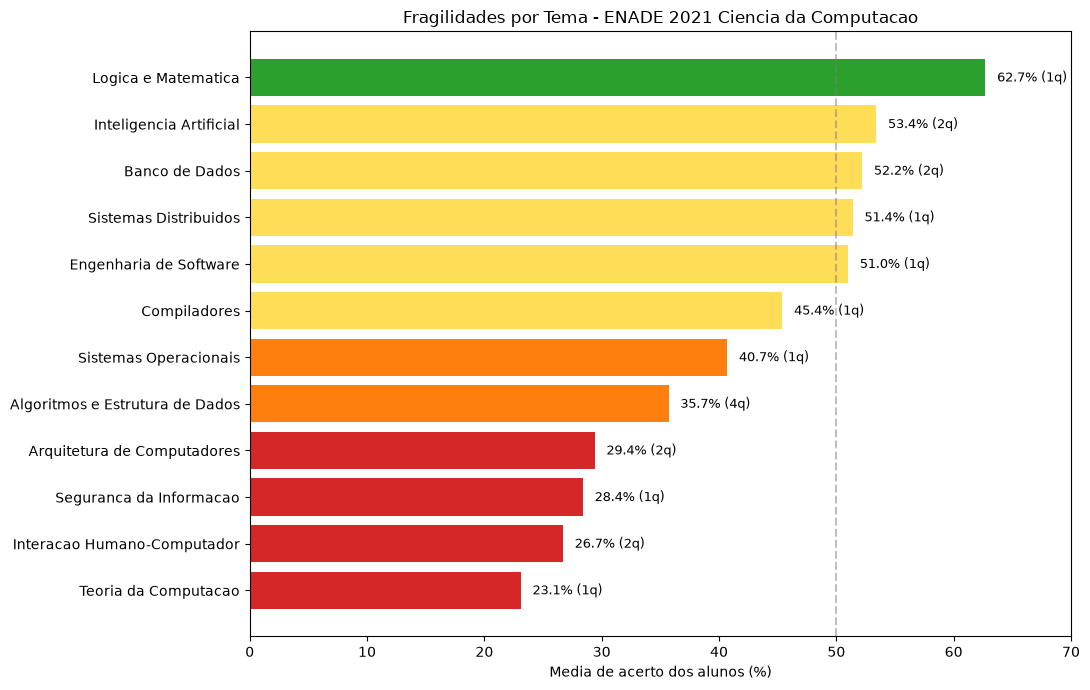

Grafico salvo em: C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\ranking_fragilidades.png


In [17]:
import matplotlib.pyplot as plt

# ============================================================
# GRAFICO: Ranking de Fragilidades por Tema
# ============================================================
ranking_grafico = ranking.sort_values("media_acerto", ascending=True)

plt.figure(figsize=(11, 7))

cores = []
for acerto in ranking_grafico["media_acerto"]:
    if acerto < 30:
        cores.append("#d62728")
    elif acerto < 45:
        cores.append("#ff7f0e")
    elif acerto < 60:
        cores.append("#ffdd57")
    else:
        cores.append("#2ca02c")

barras = plt.barh(ranking_grafico["tema"], ranking_grafico["media_acerto"], color=cores)

plt.title("Fragilidades por Tema - ENADE 2021 Ciencia da Computacao", fontsize=12)
plt.xlabel("Media de acerto dos alunos (%)")
plt.axvline(x=50, color="gray", linestyle="--", alpha=0.5)
plt.xlim(0, 70)

for barra, acerto, n in zip(barras, ranking_grafico["media_acerto"], ranking_grafico["num_questoes"]):
    plt.text(acerto + 1, barra.get_y() + barra.get_height()/2, f"{acerto}% ({n}q)", va="center", fontsize=9)

plt.tight_layout()

caminho_graf = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\ranking_fragilidades.png"
plt.savefig(caminho_graf, dpi=150)
plt.show()
print("Grafico salvo em:", caminho_graf)


In [21]:
import pandas as pd

# ============================================================
# RAG - Parte 1: Carregar os dados reais para alimentar o agente
# ============================================================
pasta_result = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados"

ranking = pd.read_csv(pasta_result + r"\ranking_fragilidades.csv")
tabela_tct = pd.read_csv(pasta_result + r"\tabela_tct_completa.csv")

# Juntar o tema (do agente) com a tabela TCT
temas_df = pd.DataFrame(resultados)
dados_completos = temas_df.merge(tabela_tct, on="questao_analise", how="left")
dados_completos = dados_completos.dropna(subset=["indice_dificuldade"])

# Montar o resumo em TEXTO usando uma LISTA de linhas (sem problematico)
linhas = []
linhas.append("RANKING DE FRAGILIDADES POR TEMA (menor acerto = maior dificuldade):")
for _, linha in ranking.iterrows():
    linhas.append(f"- {linha['tema']}: {linha['media_acerto']}% de acerto medio ({linha['num_questoes']} questao/questoes)")

linhas.append("")
linhas.append("DETALHE DAS QUESTOES MAIS DIFICEIS:")
mais_dificeis = dados_completos.sort_values("indice_dificuldade").head(5)
for _, linha in mais_dificeis.iterrows():
    pct = round(linha["indice_dificuldade"]*100, 1)
    texto_q = f"- Questao {int(linha['questao_prova'])} (tema: {linha['tema']}): {pct}% acertaram; discriminacao {round(linha['indice_discriminacao'],2)}; distrator mais marcado: alternativa {linha['distrator_mais_marcado']} ({linha['distrator_pct']}%)"
    linhas.append(texto_q)

# Juntar tudo com quebra de linha usando chr(10) - sem aspas problematicas
contexto = chr(10).join(linhas)

print("===== CONTEXTO QUE O AGENTE VAI LER =====")
print(contexto)


===== CONTEXTO QUE O AGENTE VAI LER =====
RANKING DE FRAGILIDADES POR TEMA (menor acerto = maior dificuldade):
- Teoria da Computacao: 23.1% de acerto medio (1 questao/questoes)
- Interacao Humano-Computador: 26.7% de acerto medio (2 questao/questoes)
- Seguranca da Informacao: 28.4% de acerto medio (1 questao/questoes)
- Arquitetura de Computadores: 29.4% de acerto medio (2 questao/questoes)
- Algoritmos e Estrutura de Dados: 35.7% de acerto medio (4 questao/questoes)
- Sistemas Operacionais: 40.7% de acerto medio (1 questao/questoes)
- Compiladores: 45.4% de acerto medio (1 questao/questoes)
- Engenharia de Software: 51.0% de acerto medio (1 questao/questoes)
- Sistemas Distribuidos: 51.4% de acerto medio (1 questao/questoes)
- Banco de Dados: 52.2% de acerto medio (2 questao/questoes)
- Inteligencia Artificial: 53.4% de acerto medio (2 questao/questoes)
- Logica e Matematica: 62.7% de acerto medio (1 questao/questoes)

DETALHE DAS QUESTOES MAIS DIFICEIS:
- Questao 26 (tema: Interaca

In [22]:
import ollama

# ============================================================
# RAG - Parte 2: O agente gera o diagnostico com base nos dados
# ============================================================

prompt_relatorio = f"""Voce e um especialista em avaliacao educacional e pedagogia, analisando o desempenho de estudantes de Ciencia da Computacao no ENADE 2021.

Com base EXCLUSIVAMENTE nos dados reais abaixo, escreva um diagnostico pedagogico claro e objetivo.

DADOS REAIS DA ANALISE:
{contexto}

Escreva um relatorio com estas 3 secoes:

1. DIAGNOSTICO GERAL: resuma o cenario geral de desempenho dos alunos.

2. PRINCIPAIS FRAGILIDADES: aponte os 3 temas de maior dificuldade e, para cada um, comente o que o dado sugere (use os numeros reais).

3. RECOMENDACOES: sugira acoes praticas de ensino para cada uma dessas fragilidades.

Importante: baseie-se SOMENTE nos dados fornecidos. Nao invente numeros. Escreva em portugues, de forma profissional e objetiva."""

print("O agente esta escrevendo o relatorio... (pode levar 30s a 1min)")
print("=" * 60)

resposta = ollama.chat(
    model="llama3.1:8b",
    messages=[{"role": "user", "content": prompt_relatorio}]
)

relatorio = resposta["message"]["content"]
print(relatorio)

# Salvar o relatorio num arquivo de texto
caminho_rel = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\relatorio_agente.txt"
with open(caminho_rel, "w", encoding="utf-8") as f:
    f.write(relatorio)
print()
print("=" * 60)
print("Relatorio salvo em:", caminho_rel)


O agente esta escrevendo o relatorio... (pode levar 30s a 1min)
**Relatório de Diagnóstico Pedagógico: Avaliação do Desempenho de Estudantes de Ciência da Computação no ENADE 2021**

**1. Diagnóstico Geral**

O desempenho dos estudantes de Ciência da Computação no ENADE 2021 apresenta um cenário geral de fragilidade em diversas áreas do conhecimento. Embora haja variações nos índices de acerto médio, é possível identificar algumas tendências importantes. Em geral, os estudantes apresentaram maior dificuldade em questões relacionadas a áreas mais específicas e complexas da computação, como Teoria da Computação, Interação Humano-Computador, Segurança da Informação e Arquitetura de Computadores. Já as áreas mais abrangentes, como Engenharia de Software, Sistemas Distribuídos e Banco de Dados, apresentaram índices de acerto mais elevados.

**2. Principais Fragilidades**

**a. Teoria da Computação (23,1% de acerto médio)**

O baixo índice de acerto médio em Teoria da Computação sugere que o

In [23]:
import pandas as pd

pasta_result = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados"

ranking = pd.read_csv(pasta_result + r"\ranking_fragilidades.csv")
tabela_tct = pd.read_csv(pasta_result + r"\tabela_tct_completa.csv")

temas_df = pd.DataFrame(resultados)
dados_completos = temas_df.merge(tabela_tct, on="questao_analise", how="left")
dados_completos = dados_completos.dropna(subset=["indice_dificuldade"])

# Funcao que traduz o numero da discriminacao em palavra (feito em Python, nao pela IA)
def classificar_discriminacao(d):
    if d >= 0.40:
        return "otima"
    elif d >= 0.30:
        return "boa"
    elif d >= 0.20:
        return "razoavel"
    else:
        return "fraca"

# Funcao que traduz a dificuldade em palavra
def classificar_dificuldade(p):
    if p < 0.30:
        return "muito dificil"
    elif p < 0.50:
        return "dificil"
    elif p < 0.70:
        return "media"
    else:
        return "facil"

linhas = []
linhas.append("RANKING DE FRAGILIDADES POR TEMA (menor acerto = maior dificuldade):")
for _, linha in ranking.iterrows():
    linhas.append(f"- {linha['tema']}: {linha['media_acerto']}% de acerto medio ({linha['num_questoes']} questoes)")

linhas.append("")
linhas.append("DETALHE DAS 5 QUESTOES MAIS DIFICEIS (numeracao da PROVA):")
mais_dificeis = dados_completos.sort_values("indice_dificuldade").head(5)
for _, linha in mais_dificeis.iterrows():
    pct = round(linha["indice_dificuldade"] * 100, 1)
    disc = round(linha["indice_discriminacao"], 2)
    nivel_dif = classificar_dificuldade(linha["indice_dificuldade"])
    nivel_disc = classificar_discriminacao(linha["indice_discriminacao"])
    texto_q = f"- Questao {int(linha['questao_prova'])} (tema {linha['tema']}): {pct}% acertaram (dificuldade {nivel_dif}); indice de discriminacao {disc} (classificacao: {nivel_disc}); distrator mais marcado alternativa {linha['distrator_mais_marcado']} com {linha['distrator_pct']}%"
    linhas.append(texto_q)

contexto = chr(10).join(linhas)

print("===== CONTEXTO AJUSTADO QUE O AGENTE VAI LER =====")
print(contexto)


===== CONTEXTO AJUSTADO QUE O AGENTE VAI LER =====
RANKING DE FRAGILIDADES POR TEMA (menor acerto = maior dificuldade):
- Teoria da Computacao: 23.1% de acerto medio (1 questoes)
- Interacao Humano-Computador: 26.7% de acerto medio (2 questoes)
- Seguranca da Informacao: 28.4% de acerto medio (1 questoes)
- Arquitetura de Computadores: 29.4% de acerto medio (2 questoes)
- Algoritmos e Estrutura de Dados: 35.7% de acerto medio (4 questoes)
- Sistemas Operacionais: 40.7% de acerto medio (1 questoes)
- Compiladores: 45.4% de acerto medio (1 questoes)
- Engenharia de Software: 51.0% de acerto medio (1 questoes)
- Sistemas Distribuidos: 51.4% de acerto medio (1 questoes)
- Banco de Dados: 52.2% de acerto medio (2 questoes)
- Inteligencia Artificial: 53.4% de acerto medio (2 questoes)
- Logica e Matematica: 62.7% de acerto medio (1 questoes)

DETALHE DAS 5 QUESTOES MAIS DIFICEIS (numeracao da PROVA):
- Questao 26 (tema Interacao Humano-Computador): 15.3% acertaram (dificuldade muito dificil)

In [24]:
import ollama

prompt_relatorio = f"""Voce e um especialista em avaliacao educacional analisando o desempenho de estudantes de Ciencia da Computacao no ENADE 2021.

Com base EXCLUSIVAMENTE nos dados reais abaixo, escreva um diagnostico pedagogico.

REGRAS IMPORTANTES:
- Use SEMPRE a numeracao da PROVA ao citar questoes (ex: Questao 26).
- Ao comentar a discriminacao, use EXATAMENTE a classificacao ja fornecida nos dados (fraca, razoavel, boa, otima). NAO invente outro adjetivo.
- Lembre: discriminacao FRACA significa que ate os bons alunos erraram (fragilidade coletiva ou item problematico). Discriminacao BOA/OTIMA significa que a questao separa bem quem sabe de quem nao sabe.
- Nao invente numeros. Use somente os dados fornecidos.

DADOS REAIS DA ANALISE:
{contexto}

Escreva o relatorio com 3 secoes:
1. DIAGNOSTICO GERAL: resumo do cenario de desempenho.
2. PRINCIPAIS FRAGILIDADES: os 3 temas de maior dificuldade, comentando os numeros reais e a discriminacao (com a classificacao correta).
3. RECOMENDACOES: acoes praticas de ensino para cada fragilidade.

Escreva em portugues, de forma profissional e objetiva."""

print("O agente esta reescrevendo o relatorio... (30s a 1min)")
print("=" * 60)

resposta = ollama.chat(
    model="llama3.1:8b",
    messages=[{"role": "user", "content": prompt_relatorio}]
)

relatorio = resposta["message"]["content"]
print(relatorio)

caminho_rel = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\relatorio_agente.txt"
with open(caminho_rel, "w", encoding="utf-8") as f:
    f.write(relatorio)
print()
print("=" * 60)
print("Relatorio salvo em:", caminho_rel)


O agente esta reescrevendo o relatorio... (30s a 1min)
**Relatório de Diagnóstico Pedagógico - ENADE 2021**

**1. Diagnóstico Geral**

O desempenho dos estudantes de Ciência da Computação no ENADE 2021 apresenta uma visão geral de fragilidade coletiva nas disciplinas de Teoria da Computação, Interação Humano-Computador, Segurança da Informação e Arquitetura de Computadores, com acerto médio abaixo de 30%. Já as áreas de Algoritmos e Estrutura de Dados e Sistemas Operacionais apresentam acerto médio acima de 40%, mas com questões específicas que ainda apresentam dificuldade. É importante notar que as questões mais difíceis são aquelas que apresentam fraca discriminação, o que sugere fragilidade coletiva.

**2. Principais Fragilidades**

A análise das dificuldades apresentadas pelos estudantes é crucial para identificar as áreas que necessitam de atenção especial. Além das áreas de maior dificuldade mencionadas anteriormente, é importante destacar os temas de Interação Humano-Computador,

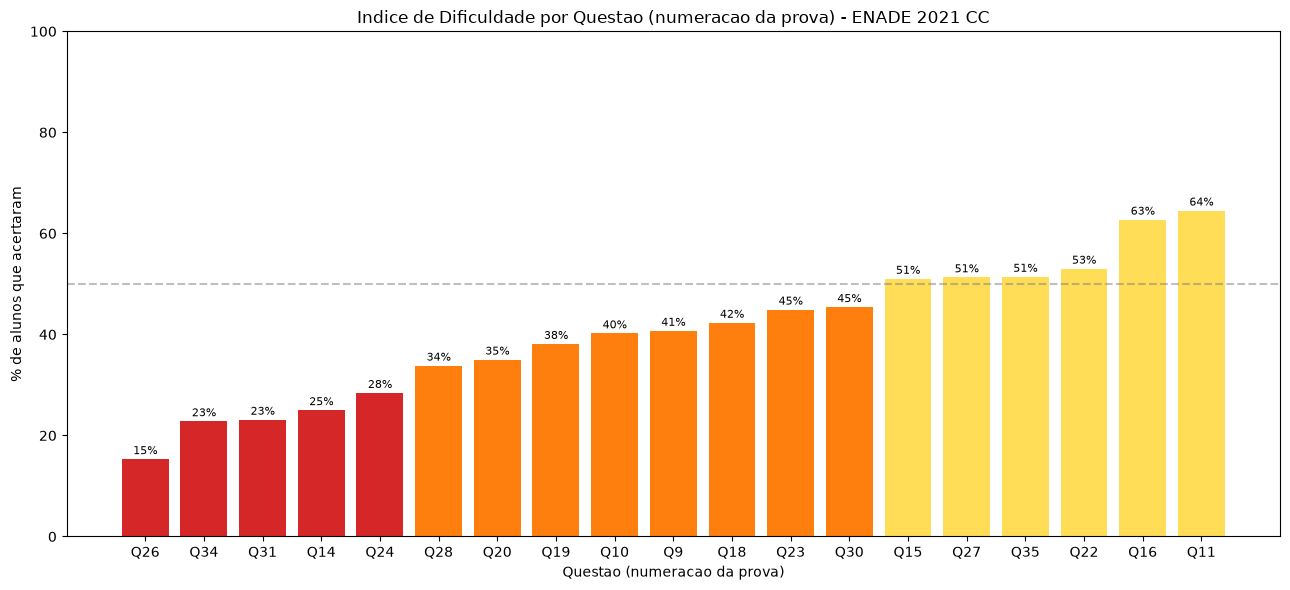

Grafico salvo em: C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\dificuldade_questoes_prova.png


In [25]:
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# GRAFICO de dificuldade por questao (numeracao da PROVA)
# ============================================================
# Usar dados_completos que ja tem tema + indicadores + questao_prova
dados_graf = dados_completos.dropna(subset=["indice_dificuldade"]).copy()
dados_graf["pct_acerto"] = (dados_graf["indice_dificuldade"] * 100).round(1)
dados_graf = dados_graf.sort_values("pct_acerto")

# Rotulo: numero da questao na PROVA
dados_graf["rotulo"] = dados_graf["questao_prova"].astype(int).map(lambda x: f"Q{x}")

plt.figure(figsize=(13, 6))

cores = []
for p in dados_graf["pct_acerto"]:
    if p < 30:
        cores.append("#d62728")
    elif p < 50:
        cores.append("#ff7f0e")
    elif p < 70:
        cores.append("#ffdd57")
    else:
        cores.append("#2ca02c")

barras = plt.bar(dados_graf["rotulo"], dados_graf["pct_acerto"], color=cores)

plt.title("Indice de Dificuldade por Questao (numeracao da prova) - ENADE 2021 CC", fontsize=12)
plt.xlabel("Questao (numeracao da prova)")
plt.ylabel("% de alunos que acertaram")
plt.axhline(y=50, color="gray", linestyle="--", alpha=0.5)
plt.ylim(0, 100)

for barra, valor in zip(barras, dados_graf["pct_acerto"]):
    plt.text(barra.get_x() + barra.get_width()/2, valor + 1, f"{valor:.0f}%", ha="center", fontsize=8)

plt.tight_layout()
caminho = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\dificuldade_questoes_prova.png"
plt.savefig(caminho, dpi=150)
plt.show()
print("Grafico salvo em:", caminho)
